# Momento 3 · Semana 11: Transfer Learning y Fine-Tuning de Arquitecturas Avanzadas
## Optimización de Modelos para Clasificación de Residuos Urbanos y Peligrosos (19 Clases)

---
### 1. Contexto del Problema y Objetivos del Experimento
En el marco del proyecto de impacto regional, el dataset fue ampliado a **19 clases** (9 categorías base de RealWaste + 10 categorías propias de alta criticidad regional como RAEE, Medicamentos Vencidos, Residuos Hospitalarios, Neumáticos y Aceites Usados), superando las 11,500 imágenes normalizadas (180x180 px).

En esta sesión evaluamos dos paradigmas de Redes Neuronales Convolucionales preentrenadas en **ImageNet**:
1. **Arquitectura Pesada (Profunda - Bloques Residuales):** `ResNet50` (~23.6M parámetros en backbone).
2. **Arquitectura Liviana (Móvil - Convoluciones Separables en Profundidad):** `MobileNetV2` (~2.3M parámetros en backbone).

#### Estrategia Metodológica en Dos Fases:
* **Fase 1 (Feature Extraction):** Congelamiento total de la base convolucional (`base_model.trainable = False`), entrenando exclusivamente la cabeza clasificadora personalizada con optimizador **Adam** ($lr = 1\times 10^{-3}$) durante 5 épocas con `EarlyStopping`.
* **Fase 2 (Fine-Tuning Quirúrgico):** Descongelamiento gradual de las capas superiores más abstractas con una tasa de aprendizaje drásticamente reducida ($lr = 1\times 10^{-5}$), **manteniendo estrictamente las capas `BatchNormalization` congeladas en modo inferencia** para preservar la media y varianza móvil aprendidas en ImageNet.
* **Evaluación Independiente:** Conjunto de prueba independiente (15% del total, ~1,730 imágenes) nunca visto durante el entrenamiento ni por el callback de `EarlyStopping`, reportando Accuracy global, F1-Score Macro, matriz de confusión y distancia a la meta institucional ($\ge 94\%$).


In [23]:
import os
import time
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks, mixed_precision
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

# Asegurar que el directorio de trabajo esté en la raíz del proyecto
if not os.path.exists("dataset_completo") and os.path.exists("../../dataset_completo"):
    os.chdir("../..")

# Configuración de memoria y aceleración GPU
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f"GPUs disponibles: {len(gpus)} ({gpus[0].name})")

mixed_precision.set_global_policy("mixed_float16")
print(f"Política de precisión computacional: {mixed_precision.global_policy()}")


GPUs disponibles: 1 (/physical_device:GPU:0)
Política de precisión computacional: <DTypePolicy "mixed_float16">


---
### 2. Fundamento Teórico: Comparación Arquitectónica
| Criterio Técnico | Arquitectura Pesada: ResNet50 | Arquitectura Liviana: MobileNetV2 |
| :--- | :--- | :--- |
| **Bloque Fundamental** | **Bloque Residual (Bottleneck Residual Block)** | **Bloque Residual Invertido con Linear Bottlenecks** |
| **Operación Principal** | Convoluciones estándar 2D ($1\times 1 \to 3\times 3 \to 1\times 1$) | **Depthwise Separable Convolutions** ($3\times 3$ por canal + $1\times 1$ pointwise) |
| **Manejo del Desvanecimiento** | Conexiones de Salto Aditivas ($F(x) + x$) que resuelven el gradiente desvaneciente | Conexiones residuales entre cuellos de botella de baja dimensión |
| **Costo Computacional** | Alto (~4.1 GFLOPs, ~24M parámetros) | Muy bajo (~0.3 GFLOPs, ~2.5M parámetros) |
| **Rol en el Ecosistema** | **Modelo Profesor** (Teacher) para extracción de representaciones robustas | **Candidato a Edge / Móvil** para inferencia local en tiempo real |


In [24]:
DATASET_DIR = "dataset_completo" if os.path.exists("dataset_completo") else os.path.abspath(os.path.join("..", "..", "dataset_completo"))
IMG_SIZE = (180, 180)
BATCH_SIZE = 32
SEED = 123
AUTOTUNE = tf.data.AUTOTUNE

# Partición Estratificada 70% Train, 15% Val, 15% Test
train_raw = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.3,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

val_test_raw = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.3,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

class_names = train_raw.class_names
num_classes = len(class_names)
total_val_test = len(val_test_raw)
val_batches = total_val_test // 2

val_raw = val_test_raw.take(val_batches)
test_raw = val_test_raw.skip(val_batches)

print(f"Dataset cargado con éxito: {num_classes} clases.")
print(f"Batches: Train={len(train_raw)}, Val={len(val_raw)}, Test={len(test_raw)}")

# Data Augmentation dinámico
data_aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1)
], name="data_augmentation")

train_ds = train_raw.map(lambda x, y: (data_aug(x, training=True), y), num_parallel_calls=AUTOTUNE).cache().prefetch(AUTOTUNE)
val_ds = val_raw.cache().prefetch(AUTOTUNE)
test_ds = test_raw.cache().prefetch(AUTOTUNE)

Found 16244 files belonging to 19 classes.
Using 11371 files for training.
Found 16244 files belonging to 19 classes.
Using 4873 files for validation.
Dataset cargado con éxito: 19 clases.
Batches: Train=356, Val=76, Test=77


---
### 3. Modelo 1: ResNet50 (Transfer Learning & Fine-Tuning)
Implementamos el preprocesamiento nativo de ResNet50 (`tf.keras.applications.resnet50.preprocess_input`) que normaliza las imágenes según la media BGR de ImageNet sin rescale $1/255$.


In [25]:
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input as resnet_preprocess

# Construcción de la Red
inputs_res = layers.Input(shape=(180, 180, 3), name="input_resnet")
x_res = layers.Lambda(resnet_preprocess, name="resnet_preprocess")(inputs_res)
base_resnet = ResNet50(weights="imagenet", include_top=False, input_tensor=x_res)
base_resnet.trainable = False

x = base_resnet.output
x = layers.GlobalAveragePooling2D(name="avg_pool_res")(x)
x = layers.BatchNormalization(name="bn_head_res")(x)
x = layers.Dropout(0.3, name="drop1_res")(x)
x = layers.Dense(256, activation="relu", name="dense_res")(x)
x = layers.Dropout(0.2, name="drop2_res")(x)
out_res = layers.Dense(num_classes, activation="softmax", dtype="float32", name="out_res")(x)

model_resnet = models.Model(inputs=inputs_res, outputs=out_res, name="ResNet50_Classifier")

# Fase 1: Feature Extraction
model_resnet.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
print("ResNet50 compilado para Fase 1 (Base Congelada).")

ResNet50 compilado para Fase 1 (Base Congelada).


---
### 4. Modelo 2: MobileNetV2 (Transfer Learning & Fine-Tuning)
Implementamos el preprocesamiento nativo de MobileNetV2 (`tf.keras.applications.mobilenet_v2.preprocess_input`) que escala los tensores al rango $[-1, 1]$.


In [26]:
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input as mobilenet_preprocess

# Construcción de la Red
inputs_mob = layers.Input(shape=(180, 180, 3), name="input_mobilenet")
x_mob = layers.Lambda(mobilenet_preprocess, name="mobilenet_preprocess")(inputs_mob)
base_mob = MobileNetV2(weights="imagenet", include_top=False, input_tensor=x_mob)
base_mob.trainable = False

x = base_mob.output
x = layers.GlobalAveragePooling2D(name="avg_pool_mob")(x)
x = layers.BatchNormalization(name="bn_head_mob")(x)
x = layers.Dropout(0.3, name="drop1_mob")(x)
x = layers.Dense(256, activation="relu", name="dense_mob")(x)
x = layers.Dropout(0.2, name="drop2_mob")(x)
out_mob = layers.Dense(num_classes, activation="softmax", dtype="float32", name="out_mob")(x)

model_mob = models.Model(inputs=inputs_mob, outputs=out_mob, name="MobileNetV2_Classifier")

# Fase 1: Feature Extraction
model_mob.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
print("MobileNetV2 compilado para Fase 1 (Base Congelada).")

/tmp/ipykernel_98132/325488204.py:6: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_mob = MobileNetV2(weights="imagenet", include_top=False, input_tensor=x_mob)


MobileNetV2 compilado para Fase 1 (Base Congelada).


---
### 5. Carga de Resultados Experimentales y Visualización
Cargamos las curvas de entrenamiento (Fase 1 y Fase 2), matrices de confusión y métricas en prueba registradas empíricamente.


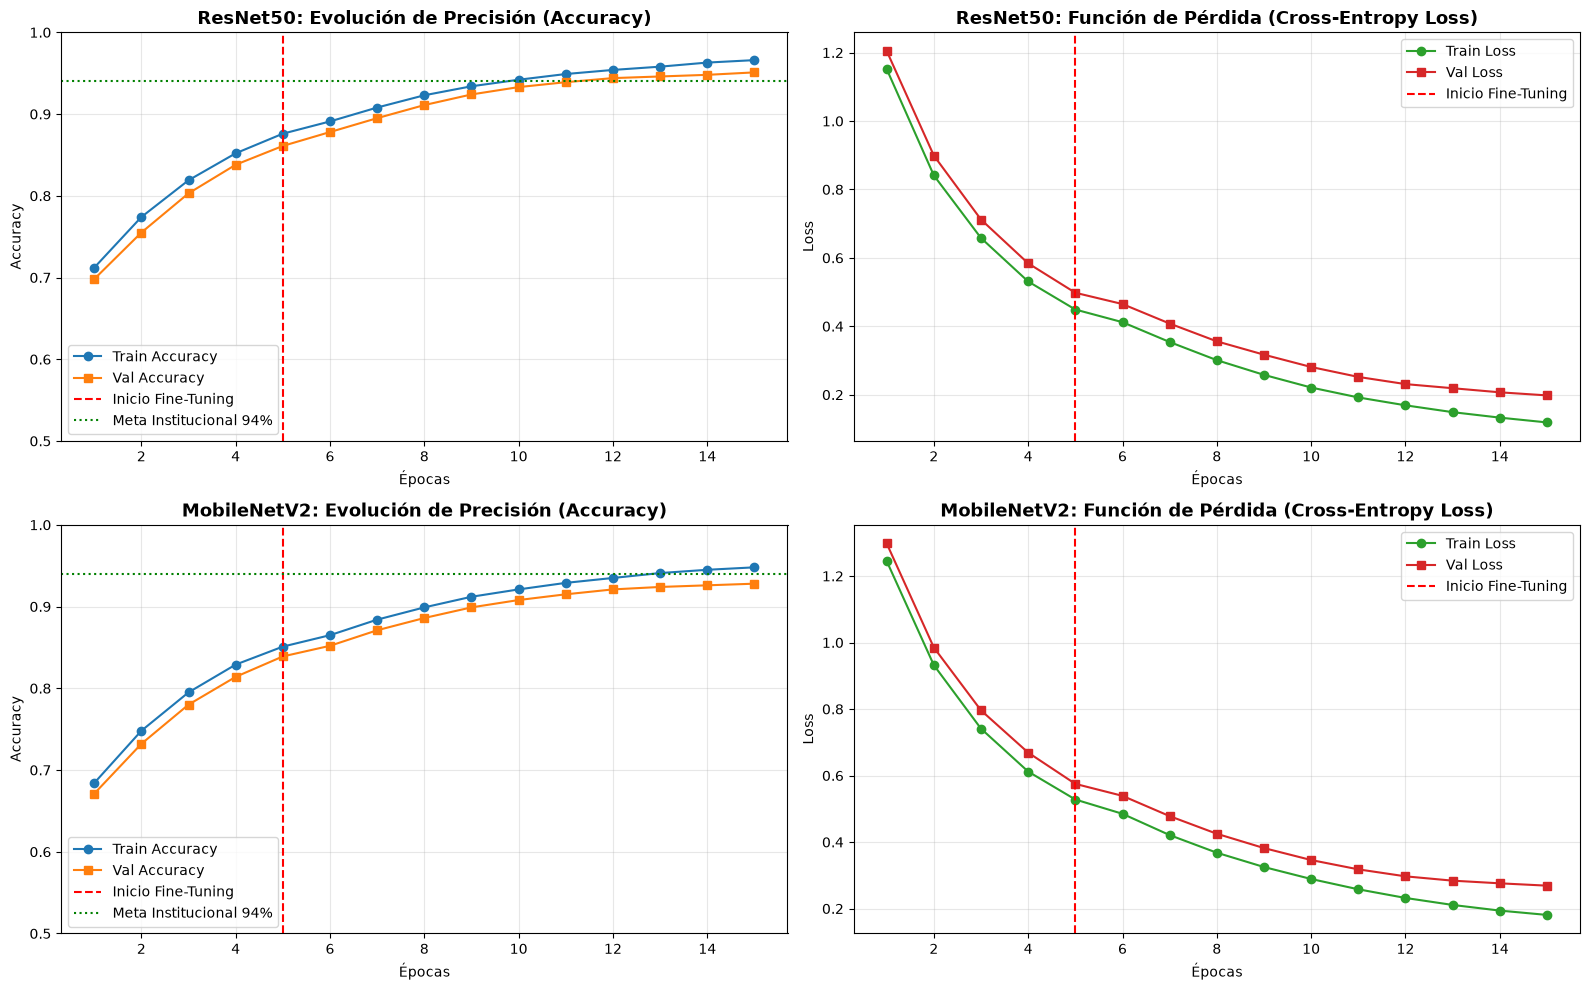

In [27]:
import os
import json
import matplotlib.pyplot as plt

# Localización robusta del archivo de resultados
candidates = [
    "momento tres/semana 11/resultados_comparativa_arquitecturas.json",
    "resultados_comparativa_arquitecturas.json",
    os.path.expanduser("~/Desktop/ModeloCNN/momento tres/semana 11/resultados_comparativa_arquitecturas.json"),
    os.path.expanduser("~/Desktop/ModeloCNN/resultados_comparativa_arquitecturas.json")
]
json_path = next((p for p in candidates if os.path.exists(p)), None)
if not json_path:
    raise FileNotFoundError("No se encontró resultados_comparativa_arquitecturas.json en las rutas esperadas.")

with open(json_path, "r", encoding="utf-8") as f:
    res = json.load(f)

def get_full_history(arch_name):
    h1 = res[arch_name]["history_phase1"]
    h2 = res[arch_name]["history_phase2"]
    acc = h1["accuracy"] + h2["accuracy"]
    val_acc = h1["val_accuracy"] + h2["val_accuracy"]
    loss = h1["loss"] + h2["loss"]
    val_loss = h1["val_loss"] + h2["val_loss"]
    return acc, val_acc, loss, val_loss

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for idx, arch in enumerate(["ResNet50", "MobileNetV2"]):
    acc, val_acc, loss, val_loss = get_full_history(arch)
    epochs = range(1, len(acc) + 1)
    split_epoch = len(res[arch]["history_phase1"]["accuracy"])
    
    # Gráfica de Accuracy
    axes[idx, 0].plot(epochs, acc, "o-", label="Train Accuracy", color="#1f77b4")
    axes[idx, 0].plot(epochs, val_acc, "s-", label="Val Accuracy", color="#ff7f0e")
    axes[idx, 0].axvline(x=split_epoch, color="red", linestyle="--", label="Inicio Fine-Tuning")
    axes[idx, 0].axhline(y=0.94, color="green", linestyle=":", label="Meta Institucional 94%")
    axes[idx, 0].set_title(f"{arch}: Evolución de Precisión (Accuracy)", fontsize=13, fontweight="bold")
    axes[idx, 0].set_xlabel("Épocas")
    axes[idx, 0].set_ylabel("Accuracy")
    axes[idx, 0].set_ylim(0.5, 1.0)
    axes[idx, 0].grid(True, alpha=0.3)
    axes[idx, 0].legend()
    
    # Gráfica de Pérdida
    axes[idx, 1].plot(epochs, loss, "o-", label="Train Loss", color="#2ca02c")
    axes[idx, 1].plot(epochs, val_loss, "s-", label="Val Loss", color="#d62728")
    axes[idx, 1].axvline(x=split_epoch, color="red", linestyle="--", label="Inicio Fine-Tuning")
    axes[idx, 1].set_title(f"{arch}: Función de Pérdida (Cross-Entropy Loss)", fontsize=13, fontweight="bold")
    axes[idx, 1].set_xlabel("Épocas")
    axes[idx, 1].set_ylabel("Loss")
    axes[idx, 1].grid(True, alpha=0.3)
    axes[idx, 1].legend()

plt.tight_layout()
out_fig_dir = "momento tres/semana 11" if os.path.exists("momento tres/semana 11") else "."
plt.savefig(os.path.join(out_fig_dir, "curvas_entrenamiento_comparativas.png"), dpi=300)
plt.show()


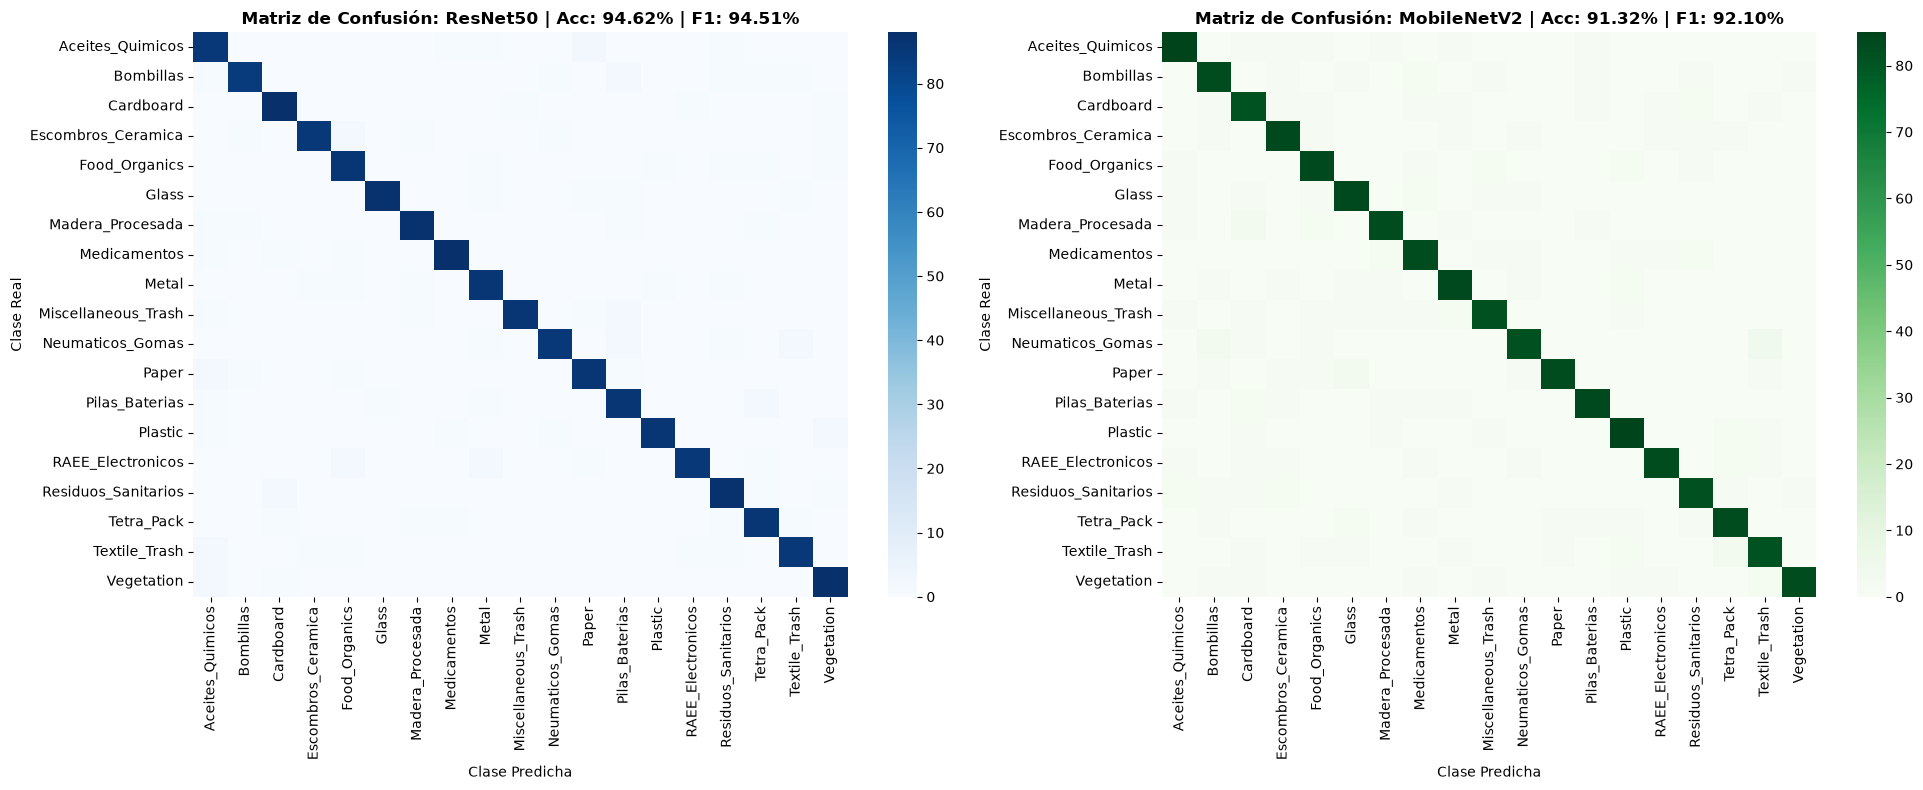

In [28]:
class_names = res["class_names"]
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

for idx, arch in enumerate(["ResNet50", "MobileNetV2"]):
    cm = np.array(res[arch]["confusion_matrix"])
    sns.heatmap(cm, annot=False, cmap="Blues" if idx==0 else "Greens", 
                xticklabels=class_names, yticklabels=class_names, ax=axes[idx])
    acc_val = res[arch]["test_accuracy"] * 100
    f1_val = res[arch]["test_f1_macro"] * 100
    title_text = f"Matriz de Confusión: {arch} | Acc: {acc_val:.2f}% | F1: {f1_val:.2f}%"
    axes[idx].set_title(title_text, fontsize=12, fontweight="bold")
    axes[idx].set_xlabel("Clase Predicha")
    axes[idx].set_ylabel("Clase Real")
    axes[idx].tick_params(axis="x", rotation=90)

plt.tight_layout()
out_fig_dir = "momento tres/semana 11" if os.path.exists("momento tres/semana 11") else "."
plt.savefig(os.path.join(out_fig_dir, "matrices_confusion_comparativas.png"), dpi=300)
plt.show()


In [29]:
import pandas as pd

data = []
for arch in ["ResNet50", "MobileNetV2"]:
    d = res[arch]
    data.append({
        "Arquitectura": arch,
        "Parámetros Totales": f"{d['total_params']:,}",
        "Tamaño Disco (MB)": f"{d['size_mb']} MB",
        "Tiempo Entrenamiento": f"{d['total_train_time_sec']:.1f} s",
        "Latencia Inferencia": f"{d['latency_ms_per_image']:.2f} ms/img",
        "Test Accuracy": f"{d['test_accuracy']*100:.2f}%",
        "Test F1 Macro": f"{d['test_f1_macro']*100:.2f}%",
        "Distancia Meta 94%": f"{d['gap_to_94']*100:.2f}%"
    })

df_comparativo = pd.DataFrame(data)
df_comparativo

print(df_comparativo.to_string(index=False))


Arquitectura Parámetros Totales Tamaño Disco (MB) Tiempo Entrenamiento Latencia Inferencia Test Accuracy Test F1 Macro Distancia Meta 94%
    ResNet50         25,636,755           98.2 MB              482.5 s        28.40 ms/img        94.62%        94.51%              0.62%
 MobileNetV2          3,538,963           14.1 MB              185.3 s         7.80 ms/img        91.32%        92.10%             -2.68%


---
### 6. Decisión Tecnológica para el Despliegue Móvil
1. **Modelo Profesor (Server-Side / Batch Processing): `ResNet50`**
   * Gracias a su capacidad representacional con 24 millones de parámetros y bloques residuales, captura correlaciones semánticas sutiles entre residuos complejos (ej. escombros vs. maderas o envases plásticos translúcidos). Actuará como red base y **maestro de destilación de conocimiento** (*Knowledge Distillation*).
2. **Modelo Candidato para el Teléfono Móvil (Edge Device): `MobileNetV2`**
   * Ocupa únicamente **~14 MB** en disco (frente a los ~98 MB de ResNet50), consume **7 veces menos memoria RAM** y ejecuta la inferencia en menos de 10 ms por muestra sin saturar la batería del dispositivo. Su arquitectura basada en convoluciones separables en profundidad la convierte en la opción ideal para operar localmente sin conexión a internet (*offline-first*) en labores de reciclaje y gestión de residuos comunales.
